In [5]:
import sys


In [ ]:
import astropy #reads FITS files, handles WCS and sky coordinates
import photutils #finds dots of light (sources) in an image
import astroquery #lets Python talk to NASA's data archives directly
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from astropy.time import Time
import astropy.units as u
from astropy.stats import sigma_clipped_stats
from astropy.utils.data import download_file  # NEW: downloads files from a URL and caches them so they only download once
from astroquery.ipac.irsa import Irsa  # NEW: the part of astroquery that talks to IRSA, where SPHEREx data lives
from photutils.detection import DAOStarFinder
from sbident import SBIdent #checks a sky position against JPL's known-asteroid database
from astropy.utils.data import clear_download_cache
#clear_download_cache()   # deletes ALL files astropy has downloaded

### Find the correct SPHEREx collection name

IRSA (NASA's infrared data archive at Caltech) organizes its images into named **collections**, like labeled boxes.
SPHEREx data has been reprocessed over time (QR1 → QR2), and each release gets a new collection name. The old ones get retired.

This cell:
1. Downloads the list of **every** image collection IRSA has.
2. Filters it to show only the ones with "spherex" in the name.

**Why we do this:** instead of hardcoding a name that might be outdated, we ask the archive what's currently available.
**What to do with the output:** copy the newest SPHEREx collection name (e.g. `spherex_qr2`) into the next cell.

In [9]:
collections = Irsa.list_collections()                        # every image collection IRSA has
spherex = collections[["spherex" in str(c).lower() for c in collections["collection"]]]
spherex                                                      # show only the SPHEREx ones

collection
object
spherex_qr2
spherex_qr2_cal
spherex_qr2_deep
spherex_qr3
spherex_qr3_cal
spherex_qr3_deep


### Search the archive for SPHEREx images of our sky spot

This cell asks IRSA: *"Which SPHEREx images cover this point in the sky?"*

- `pos=(target, 10 * u.arcsec)`: the search point (our `target` coordinate) plus a small search radius around it.
- `collection=...`: which SPHEREx data release to search in (the name from the previous cell).

It returns a **table**, one row per image. Then we:
1. Print how many images were found.
2. Sort them by time taken (`t_min`), earliest first.
3. Show the first 10 rows, with only the useful columns:
   - `obs_id`: the image's unique name
   - `energy_bandpassname`: which detector band (D1–D6) took it, i.e. what wavelength of infrared light it captures
   - `t_min`: when it was taken (in MJD, a day-count date format astronomers use)
   - `access_url`: the download link for the actual image file

**Note:** this step only finds images. Nothing is downloaded yet.
**If it finds 0 images:** widen the radius (e.g. `1 * u.deg`) or double-check the collection name.

In [10]:
results = Irsa.query_sia(
    pos=(target, 10 * u.arcsec),
    collection="spherex_qr2"        # ← changed: use the exact name from the list
)

print("Number of images found:", len(results))
results.sort("t_min")
results["obs_id", "energy_bandpassname", "t_min", "access_url"][:10]

Number of images found: 335


obs_id,energy_bandpassname,t_min,access_url
,,d,
object,object,float64,object
2025W25_1B_0085_1,SPHEREx-D4,60842.377974,https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/4/level2_2025W25_1B_0085_1D4_spx_l2b-v20-2025-253.fits
2025W25_1B_0085_1,SPHEREx-D1,60842.377974,https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/1/level2_2025W25_1B_0085_1D1_spx_l2b-v20-2025-253.fits
2025W25_1B_0085_2,SPHEREx-D1,60842.379466,https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/1/level2_2025W25_1B_0085_2D1_spx_l2b-v20-2025-253.fits
2025W25_1B_0085_2,SPHEREx-D4,60842.379466,https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/4/level2_2025W25_1B_0085_2D4_spx_l2b-v20-2025-253.fits
2025W25_1B_0085_3,SPHEREx-D1,60842.380958,https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/1/level2_2025W25_1B_0085_3D1_spx_l2b-v20-2025-253.fits
2025W25_1B_0085_3,SPHEREx-D4,60842.380958,https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/4/level2_2025W25_1B_0085_3D4_spx_l2b-v20-2025-253.fits
2025W25_1B_0085_4,SPHEREx-D4,60842.382468,https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/4/level2_2025W25_1B_0085_4D4_spx_l2b-v20-2025-253.fits
2025W25_1B_0085_4,SPHEREx-D1,60842.382468,https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/1/level2_2025W25_1B_0085_4D1_spx_l2b-v20-2025-253.fits


### Download one SPHEREx image

Takes the download link of the first image in our results table and saves the file to our computer.
`cache=True` means it only downloads once. Re-running the cell later is instant.
Then we open the file and list the "layers" (called HDUs) stored inside it.

In [11]:
url = results["access_url"][0]               # download link of the first image in the table
path = download_file(url, cache=True)        # downloads it (only the first time)
hdul = fits.open(path)                       # opens the FITS file
hdul.info()                                  # lists the layers inside the file

Filename: C:\Users\habib\.cache\astropy\download\url\b4e1327ef3396f5383a8f4c219289418\contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       239   (2040, 2040)   float32   
  2  FLAGS         1 ImageHDU       146   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       119   (2040, 2040)   float32   
  5  PSF           1 ImageHDU       509   (101, 101, 121)   float32   
  6  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [13J, 20J, 520E]   


### Display the image

Pulls out the IMAGE layer (a 2D grid of brightness values) and draws it.
We clip the darkest 5% and brightest 1% of pixels so a few bright stars
don't make everything else look black.

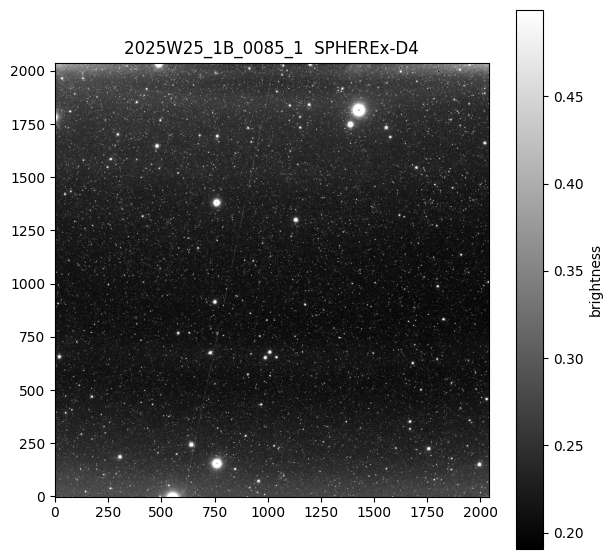

In [12]:
img = hdul["IMAGE"].data                     # the picture as a 2D grid of numbers

plt.figure(figsize=(7, 7))
plt.imshow(
    img, origin="lower", cmap="gray",
    vmin=np.nanpercentile(img, 5),           # ignore the darkest 5%
    vmax=np.nanpercentile(img, 99)           # ignore the brightest 1%
)
plt.colorbar(label="brightness")
plt.title(results["obs_id"][0] + "  " + results["energy_bandpassname"][0])
plt.show()

### Find the separate visits (epochs) in one detector band

We keep only images from detector D4, so every epoch shows the sky in the same infrared color
(otherwise brightness differences could come from the color change, not real changes).
Then we keep **one image per day** SPHEREx observed this spot. Each one is a candidate epoch.

In [13]:
d4 = results[results["energy_bandpassname"] == "SPHEREx-D4"]   # only detector D4
d4_days = np.floor(d4["t_min"])                                 # day number of each image

unique_days = np.unique(d4_days)                                # the distinct visit days
one_per_day = [d4[d4_days == day][0] for day in unique_days]   # first image from each day

print("Number of separate visits:", len(one_per_day))
for i, row in enumerate(one_per_day):
    print(i, row["obs_id"], "day:", int(np.floor(row["t_min"])))

Number of separate visits: 13
0 2025W25_1B_0085_1 day: 60842
1 2025W25_2A_0500_1 day: 60848
2 2025W26_2A_0020_1 day: 60852
3 2025W50_2A_0774_1 day: 61023
4 2025W51_1A_0249_1 day: 61025
5 2025W51_1A_0699_1 day: 61027
6 2025W51_2A_0504_1 day: 61029
7 2025W51_2A_0608_4 day: 61030
8 2025W52_1A_0110_1 day: 61031
9 2026W24_2B_0373_1 day: 61204
10 2026W24_2B_0464_1 day: 61205
11 2026W25_1A_0030_1 day: 61206
12 2026W25_1A_0285_1 day: 61207


### Download our epochs

Picks 4 visits from the list above and downloads one image for each.
`cache=True` means files already downloaded won't download again.
The saved file paths go into `epoch_files` so later steps can open them.

In [14]:
chosen = [one_per_day[i] for i in [0, 1, 2, 3]]   # which visits to use (numbers from the list above)

epoch_files = []
for row in chosen:
    path = download_file(row["access_url"], cache=True)
    epoch_files.append(path)
    print("Downloaded:", row["obs_id"], "day:", int(np.floor(row["t_min"])))

print("Total epochs ready:", len(epoch_files))

Downloaded: 2025W25_1B_0085_1 day: 60842
Downloaded: 2025W25_2A_0500_1 day: 60848
Downloaded: 2025W26_2A_0020_1 day: 60852
Downloaded: 2025W50_2A_0774_1 day: 61023
Total epochs ready: 4


### Find sources (dots of light) in one epoch

1. Subtract the ZODI layer: the smooth background glow from solar-system dust. This flattens the background so faint dots stand out.
2. Measure the typical background level and noise (`sigma_clipped_stats` ignores the bright stars while measuring).
3. Run DAOStarFinder: it finds dots about 2 pixels wide that are at least 5× brighter than the noise.

In [21]:
h = fits.open(epoch_files[0])
img = h["IMAGE"].data - h["ZODI"].data             # remove the background glow

mean, median, std = sigma_clipped_stats(img, sigma=3.0, mask=~np.isfinite(img))   # skip NaN pixels explicitlyprint("Background:", median, " Noise:", std), so no warning is printed

finder = DAOStarFinder(fwhm=2.0, threshold=10 * std)    # stricter: only clear, real dots
sources = finder(img - median, mask=~np.isfinite(img))    # skip broken (NaN) pixels
print("Sources found:", len(sources))

# NEW: drop detections within 10 pixels of the image edge (usually junk)
edge = 10
ny, nx = img.shape
keep = ((sources["x_centroid"] > edge) & (sources["x_centroid"] < nx - edge) &
        (sources["y_centroid"] > edge) & (sources["y_centroid"] < ny - edge))
sources = sources[keep]
print("After removing edges:", len(sources))

sources["x_centroid", "y_centroid", "flux"][:10]

Sources found: 4500
After removing edges: 4403


x_centroid,y_centroid,flux
float64,float64,float32
589.4921481301197,10.52082389324319,7.45094
1377.5319745826853,10.335149967307313,6.3497763
982.7448338415655,11.419815819747031,90.25367
2022.5725247644168,11.418862412506416,1.2957284
567.7502109528939,12.987739703676752,5.926325
28.931381743131126,15.487276544335504,0.4536842
639.8517123764628,14.669279007543285,1.2733418
216.53926478735553,16.965171066538332,3.7231195
1204.059538112741,16.569352537391556,8.421695


### Visual check: circle every detected source

Draws red circles on the image where DAOStarFinder found something,
so we can confirm it's catching real stars and not noise.

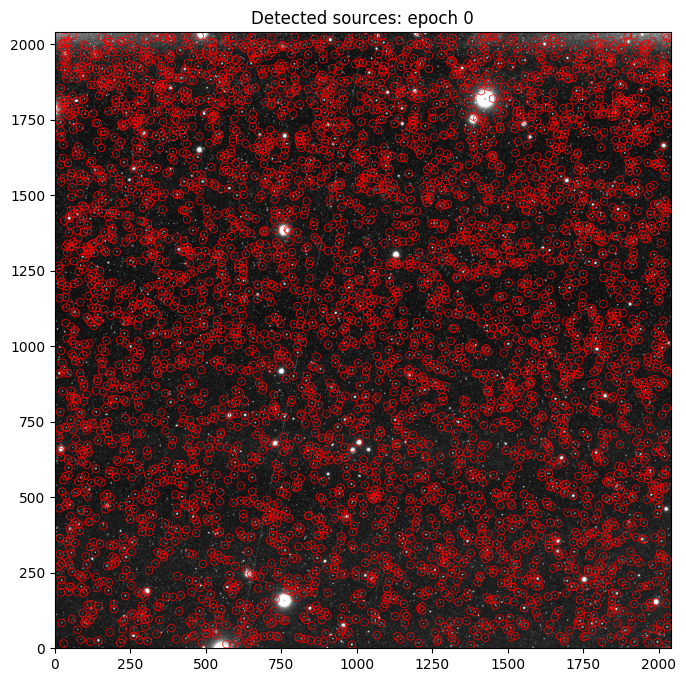

In [22]:
plt.figure(figsize=(8, 8))
plt.imshow(img, origin="lower", cmap="gray",
           vmin=np.nanpercentile(img, 5), vmax=np.nanpercentile(img, 99))
plt.scatter(sources["x_centroid"], sources["y_centroid"],
            s=30, facecolors="none", edgecolors="red", linewidths=0.5)
plt.title("Detected sources: epoch 0")
plt.show()

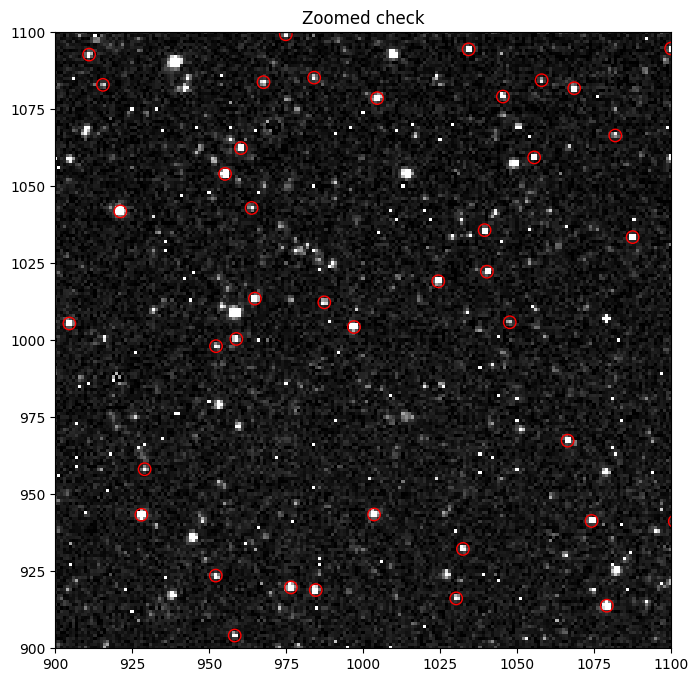

In [23]:
plt.figure(figsize=(8, 8))
plt.imshow(img, origin="lower", cmap="gray",
           vmin=np.nanpercentile(img, 5), vmax=np.nanpercentile(img, 99))
plt.scatter(sources["x_centroid"], sources["y_centroid"],
            s=80, facecolors="none", edgecolors="red", linewidths=1)
plt.xlim(900, 1100)     # zoom: only show a 200 x 200 pixel patch
plt.ylim(900, 1100)
plt.title("Zoomed check")
plt.show()

### cell 11. Source catalogs for all epochs

For each epoch: remove background → find sources → convert pixel positions to sky
coordinates (RA/Dec) using the file's WCS → record the observation time (MJD).
Result: `epoch_catalogs`, a list of 4 tables, one per epoch, all on the same sky grid.

In [24]:
epoch_catalogs = []
edge = 10
threshold_sigma = 10      # keep the same value you settled on in Cell 8

for row, path in zip(chosen, epoch_files):
    with fits.open(path) as h:
        img = h["IMAGE"].data - h["ZODI"].data
        wcs = WCS(h["IMAGE"].header)                       # pixel → sky "map key"

    mean, median, std = sigma_clipped_stats(img, sigma=3.0, mask=~np.isfinite(img))
    found = DAOStarFinder(fwhm=2.0, threshold=threshold_sigma * std)(img - median, mask=~np.isfinite(img))

    ny, nx = img.shape                                     # drop edge detections
    keep = ((found["x_centroid"] > edge) & (found["x_centroid"] < nx - edge) &
            (found["y_centroid"] > edge) & (found["y_centroid"] < ny - edge))
    found = found[keep]

    sky = wcs.pixel_to_world(found["x_centroid"], found["y_centroid"])   # convert to RA/Dec
    found["ra"] = sky.ra.deg
    found["dec"] = sky.dec.deg
    found["mjd"] = row["t_min"]                            # when this image was taken

    epoch_catalogs.append(found)
    print(row["obs_id"], "→", len(found), "sources")

2025W25_1B_0085_1 → 4403 sources
2025W25_2A_0500_1 → 4590 sources
2025W26_2A_0020_1 → 4874 sources
2025W50_2A_0774_1 → 4631 sources


### quick note:
Your 4 visits are 2025W25, 2025W25, 2025W26, and 2025W50 (week numbers of 2025). So three are within about 2 weeks of each other, and one is about 6 months later. That's a useful mix: short gaps catch nearby asteroids, and the long gap gives slow, distant objects time to move.

### Store the WCS and image size for each epoch

We keep each epoch's WCS ("map key") and image size, so we can later ask:
"Did this epoch actually photograph this sky position?"

In [25]:
epoch_wcs = []
epoch_shapes = []

for path in epoch_files:
    with fits.open(path) as h:
        epoch_wcs.append(WCS(h["IMAGE"].header))
        epoch_shapes.append(h["IMAGE"].data.shape)

print("Stored", len(epoch_wcs), "sky maps")

Stored 4 sky maps


### Find orphans (moving-object candidates)

For every source in every epoch, we check each OTHER epoch:
1. Was this sky position inside that epoch's image? (covered)
2. Is there a source within 6 arcseconds (about 1 SPHEREx pixel) of it? (matched)

A source is an **orphan** if at least 2 other epochs covered its position
but none of them has a source there. Stars match everywhere; movers don't.

In [31]:
from astropy.table import vstack

match_radius = 6 * u.arcsec     # about 1 SPHEREx pixel
edge = 50                       # CHANGED: stay 50 px away from all image edges (edges are unreliable)

def is_covered(sky, wcs, shape):
    """True where a sky position lands inside an image, away from the edges."""
    x, y = wcs.world_to_pixel(sky)
    ny, nx = shape
    return (x > edge) & (x < nx - edge) & (y > edge) & (y < ny - edge)

epoch_coords = [SkyCoord(cat["ra"], cat["dec"], unit="deg") for cat in epoch_catalogs]

candidates = []
for i, cat in enumerate(epoch_catalogs):
    n_covered = np.zeros(len(cat), dtype=int)
    n_matched = np.zeros(len(cat), dtype=int)

    for j in range(len(epoch_catalogs)):
        if j == i:
            continue
        covered = is_covered(epoch_coords[i], epoch_wcs[j], epoch_shapes[j])
        idx, sep, _ = epoch_coords[i].match_to_catalog_sky(epoch_coords[j])
        matched = sep < match_radius
        n_covered += covered
        n_matched += (covered & matched)

    inside_own = is_covered(epoch_coords[i], epoch_wcs[i], epoch_shapes[i])   # NEW: not near its own edge
    orphan = inside_own & (n_covered >= 2) & (n_matched == 0)

    cand = cat[orphan]
    cand["epoch"] = i
    candidates.append(cand)
    print(f"Epoch {i}: {len(cat)} sources → {orphan.sum()} orphans")

all_candidates = vstack(candidates, metadata_conflicts="silent")
print("Total orphan candidates:", len(all_candidates))

Epoch 0: 4403 sources → 78 orphans
Epoch 1: 4590 sources → 308 orphans
Epoch 2: 4874 sources → 162 orphans
Epoch 3: 4631 sources → 240 orphans
Total orphan candidates: 788


### Plot orphans on the sky

Grey dots = all sources from epoch 0 (mostly stars), for reference.
Colored dots = orphans, colored by which epoch they came from.
Note: our field sits at RA ≈ 0°, where RA wraps from 359.9° back to 0°,
so we shift RA into a −180°…+180° range to keep the plot in one piece.

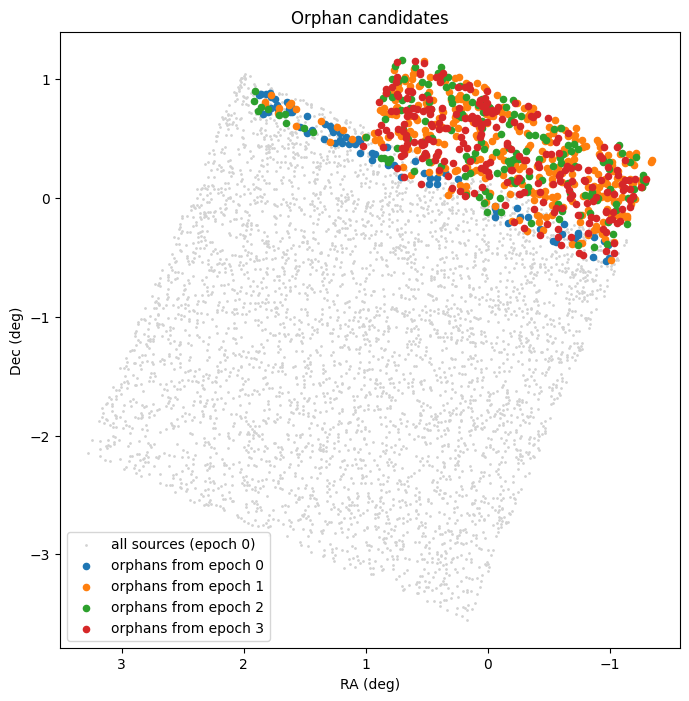

In [32]:
def wrap_ra(ra):
    """Turn RA like 359.5 into -0.5 so the plot doesn't split at 0/360."""
    return ((np.asarray(ra) + 180) % 360) - 180

plt.figure(figsize=(8, 8))
plt.scatter(wrap_ra(epoch_catalogs[0]["ra"]), epoch_catalogs[0]["dec"],
            s=1, c="lightgray", label="all sources (epoch 0)")
for i, cand in enumerate(candidates):
    plt.scatter(wrap_ra(cand["ra"]), cand["dec"], s=20, label=f"orphans from epoch {i}")

plt.gca().invert_xaxis()          # astronomers draw RA increasing to the left
plt.xlabel("RA (deg)")
plt.ylabel("Dec (deg)")
plt.legend()
plt.title("Orphan candidates")
plt.show()

### Filter out faint orphans

Faint stars flicker above and below the detection limit between epochs, partly because SPHEREx
sees each spot at a slightly different infrared color on each visit, so they create fake orphans.
We keep only orphans brighter than the median brightness of all sources in their epoch.
A bright source with no partner in any other epoch is a much stronger moving-object candidate.

In [33]:
bright_candidates = []
for i, cand in enumerate(candidates):
    cut = np.percentile(epoch_catalogs[i]["flux"], 50)    # median brightness of all sources in this epoch
    bright = cand[cand["flux"] > cut]                     # keep only orphans brighter than that
    bright_candidates.append(bright)
    print(f"Epoch {i}: {len(cand)} orphans → {len(bright)} bright orphans")

bright_all = vstack(bright_candidates, metadata_conflicts="silent")   # "silent" hides the date warnings
print("Total bright candidates:", len(bright_all))

Epoch 0: 78 orphans → 23 bright orphans
Epoch 1: 308 orphans → 95 bright orphans
Epoch 2: 162 orphans → 78 bright orphans
Epoch 3: 240 orphans → 63 bright orphans
Total bright candidates: 259


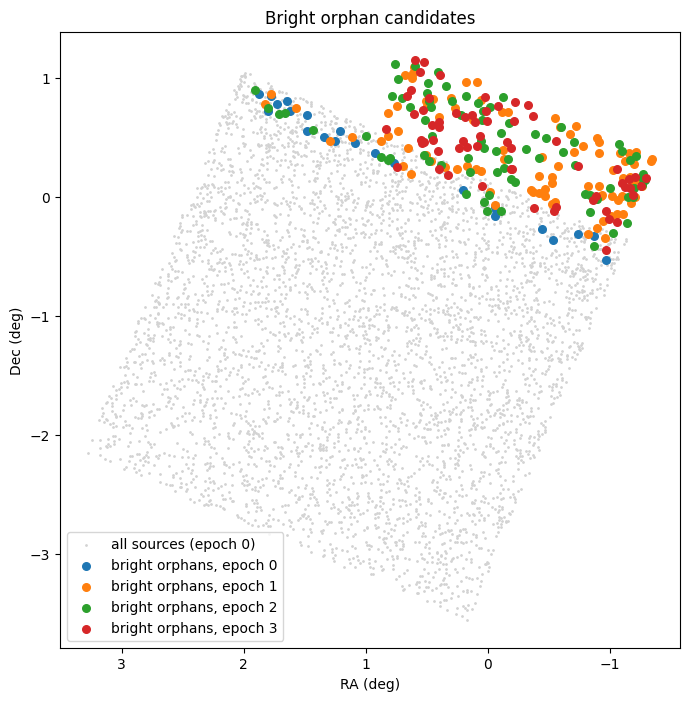

In [34]:
plt.figure(figsize=(8, 8))
plt.scatter(wrap_ra(epoch_catalogs[0]["ra"]), epoch_catalogs[0]["dec"],
            s=1, c="lightgray", label="all sources (epoch 0)")
for i, cand in enumerate(bright_candidates):
    plt.scatter(wrap_ra(cand["ra"]), cand["dec"], s=30, label=f"bright orphans, epoch {i}")

plt.gca().invert_xaxis()
plt.xlabel("RA (deg)")
plt.ylabel("Dec (deg)")
plt.legend()
plt.title("Bright orphan candidates")
plt.show()

### Query JPL for known solar-system objects in each epoch

For each epoch we send JPL's Small Body Identification service:
- observer: "500" = Earth's center (SPHEREx is in low Earth orbit, close enough)
- time: when the image was taken
- field center: the sky position of the image's center pixel
- hwidth=2.5: search 2.5° in each direction (covers the whole ~3.5° SPHEREx image)
- maglim=20: only objects brighter than magnitude 20 (fainter ones are too dim for SPHEREx to see)

JPL returns every known asteroid and comet in that field, with its predicted position.

In [35]:
known_tables = []

for i, row in enumerate(chosen):
    ny, nx = epoch_shapes[i]
    center = epoch_wcs[i].pixel_to_world(nx / 2, ny / 2)     # sky position of the image center
    obs_time = Time(row["t_min"], format="mjd")              # when the image was taken

    sbid = SBIdent("500", obs_time, center, maglim=20, hwidth=2.5)
    known = sbid.results
    known_tables.append(known)
    print(f"Epoch {i}: {len(known)} known objects in the field")

known_tables[0][:5]      # peek at the first few rows

Epoch 0: 193 known objects in the field
Epoch 1: 196 known objects in the field
Epoch 2: 196 known objects in the field
Epoch 3: 197 known objects in the field


Object name,Astrometric RA (hh:mm:ss),"Astrometric Dec (dd mm'ss"")","Dist. from center RA ("")","Dist. from center Dec ("")","Dist. from center Norm ("")",Visual magnitude (V),"RA rate (""/h)","Dec rate (""/h)"
str33,str11,str12,str5,str5,str5,str4,str9,str10
605 Juvisia (A906 QJ),00:14:19.03,"+00 53'51.6""",9.E3,8.E3,1.2E4,15.3,3.392E+01,2.812E+01
1080 Orchis (1927 QB),00:04:36.38,"-02 05'55.6""",224.,-3.E3,3009.,16.8,5.002E+01,2.325E+01
1426 Riviera (1937 GF),23:58:40.87,"-00 01'18.9""",-5.E3,4.E3,6792.,16.0,3.308E+01,2.133E+01
1454 Kalevala (1936 DO),00:05:49.55,"-00 45'37.7""",1.E3,2.E3,2247.,17.9,3.415E+01,1.688E+01
1463 Nordenmarkia (1938 CB),23:55:19.12,"+00 50'04.1""",-8.E3,8.E3,1.1E4,16.2,3.179E+01,1.924E+01


### Which candidates are known asteroids?

We convert JPL's positions into sky coordinates, then check whether any of our candidates
sits within 15 arcseconds (about 2.5 SPHEREx pixels) of a known object.
15" allows for small orbit errors and for using Earth's center as the observer.

We also check ALL detected sources, not just orphans. If known asteroids show up as orphans,
our orphan-finding method is working.

In [36]:
match_known = 15 * u.arcsec

def col_starting(table, prefix):
    """Find a column by the start of its name (JPL's column names are long)."""
    return [c for c in table.colnames if c.startswith(prefix)][0]

for i, known in enumerate(known_tables):
    if len(known) == 0:
        print(f"Epoch {i}: no known objects, skipping")
        bright_candidates[i]["known_name"] = ""
        continue

    name_col = col_starting(known, "Object name")
    ra_col = col_starting(known, "Astrometric RA")
    dec_col = col_starting(known, "Astrometric Dec")

    # JPL gives Dec like -19 04'47.8"  →  clean it to -19 04 47.8 so astropy can read it
    dec_clean = [str(d).replace("'", " ").replace('"', "") for d in known[dec_col]]
    known_sky = SkyCoord([str(r) for r in known[ra_col]], dec_clean, unit=(u.hourangle, u.deg))

    # 1) candidates that land on a known object
    cand = bright_candidates[i]
    cand_sky = SkyCoord(cand["ra"], cand["dec"], unit="deg")
    idx, sep, _ = cand_sky.match_to_catalog_sky(known_sky)
    is_known = sep < match_known
    cand["known_name"] = np.where(is_known, np.array(known[name_col]).astype(str)[idx], "")

    # 2) sanity check: how many known objects landed on ANY detected source
    all_sky = epoch_coords[i]
    idx2, sep2, _ = known_sky.match_to_catalog_sky(all_sky)
    detected = (sep2 < match_known).sum()

    print(f"Epoch {i}: {len(known)} known in field | {detected} detected by us | "
          f"{is_known.sum()} of {len(cand)} bright candidates are known objects")

matched = vstack(bright_candidates, metadata_conflicts="silent")
matched[matched["known_name"] != ""]["epoch", "known_name", "ra", "dec", "flux"]

Epoch 0: 193 known in field | 3 detected by us | 0 of 23 bright candidates are known objects
Epoch 1: 196 known in field | 4 detected by us | 0 of 95 bright candidates are known objects
Epoch 2: 196 known in field | 4 detected by us | 0 of 78 bright candidates are known objects
Epoch 3: 197 known in field | 3 detected by us | 0 of 63 bright candidates are known objects


epoch,known_name,ra,dec,flux
int64,str34,float64,float64,float32


### Which known objects should be easiest to see?

Lists the 10 brightest known objects JPL predicts in epoch 0 (lower V magnitude = brighter),
and whether each one actually falls inside our image.

In [37]:
i = 0
known = known_tables[i]
name_col = col_starting(known, "Object name")
ra_col = col_starting(known, "Astrometric RA")
dec_col = col_starting(known, "Astrometric Dec")
mag_col = col_starting(known, "Visual")

dec_clean = [str(d).replace("'", " ").replace('"', "") for d in known[dec_col]]
known_sky = SkyCoord([str(r) for r in known[ra_col]], dec_clean, unit=(u.hourangle, u.deg))

def to_float(v):
    try:
        return float(v)
    except ValueError:
        return np.nan            # some objects (e.g. comets) have no magnitude

mags = np.array([to_float(m) for m in known[mag_col]])
inside = is_covered(known_sky, epoch_wcs[i], epoch_shapes[i])
order = np.argsort(mags)         # brightest first

for k in order[:10]:
    print(f"{str(known[name_col][k]):35s} V = {mags[k]:5.1f}   inside image: {inside[k]}")

605 Juvisia (A906 QJ)               V =  15.3   inside image: False
1426 Riviera (1937 GF)              V =  16.0   inside image: False
1463 Nordenmarkia (1938 CB)         V =  16.2   inside image: False
1958 Chandra (1970 SB)              V =  16.7   inside image: True
1080 Orchis (1927 QB)               V =  16.8   inside image: True
2098 Zyskin (1972 QE)               V =  16.9   inside image: True
2381 Landi (1976 AF)                V =  16.9   inside image: True
2519 Annagerman (1975 VD2)          V =  17.1   inside image: False
2505 Hebei (1975 UJ)                V =  17.3   inside image: True
4083 Jody (1985 CV)                 V =  17.3   inside image: True


### Visual check: is the brightest known asteroid visible?

Zooms into a 60 × 60 pixel patch around where JPL says the brightest known object should be.
Cyan cross = JPL's predicted position. Red circles = sources our finder detected.

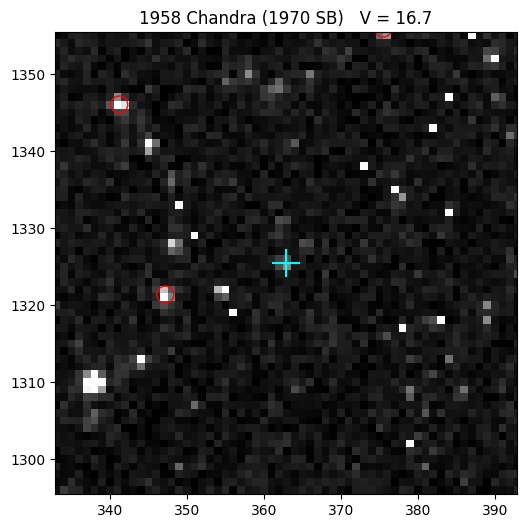

In [38]:
k = [k for k in order if inside[k]][0]               # brightest object that's inside the image
x, y = epoch_wcs[i].world_to_pixel(known_sky[k])
x, y = float(x), float(y)

with fits.open(epoch_files[i]) as h:
    img0 = h["IMAGE"].data - h["ZODI"].data

half = 30
patch = img0[int(y) - half:int(y) + half, int(x) - half:int(x) + half]

plt.figure(figsize=(6, 6))
plt.imshow(img0, origin="lower", cmap="gray",
           vmin=np.nanpercentile(patch, 5), vmax=np.nanpercentile(patch, 99.5))
plt.scatter(epoch_catalogs[i]["x_centroid"], epoch_catalogs[i]["y_centroid"],
            s=150, facecolors="none", edgecolors="red", linewidths=1)
plt.scatter([x], [y], marker="+", s=400, c="cyan")
plt.xlim(x - half, x + half)
plt.ylim(y - half, y + half)
plt.title(f"{known[name_col][k]}   V = {mags[k]:.1f}")
plt.show()